In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/baleshsingh/wine-reviews-analysis/winemag-data-130k-v2.csv


In [3]:
df = pd.read_csv("/kaggle/input/datasets/baleshsingh/wine-reviews-analysis/winemag-data-130k-v2.csv",index_col = 0)


# Type of dataset,how many rows and colums


In [4]:
df.info()
df.shape
df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 129971 entries, 0 to 129970
Data columns (total 13 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   country                129908 non-null  object 
 1   description            129971 non-null  object 
 2   designation            92506 non-null   object 
 3   points                 129971 non-null  int64  
 4   price                  120975 non-null  float64
 5   province               129908 non-null  object 
 6   region_1               108724 non-null  object 
 7   region_2               50511 non-null   object 
 8   taster_name            103727 non-null  object 
 9   taster_twitter_handle  98758 non-null   object 
 10  title                  129971 non-null  object 
 11  variety                129970 non-null  object 
 12  winery                 129971 non-null  object 
dtypes: float64(1), int64(1), object(11)
memory usage: 13.9+ MB


,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,NaN,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia
1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos
2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm
3,US,"Pineapple rind, lemon pith and orange blossom ...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,NaN,Alexander Peartree,NaN,St. Julian 2013 Reserve Late Harvest Riesling ...,Riesling,St. Julian
4,US,"Much like the regular bottling from 2012, this...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,Pinot Noir,Sweet Cheeks


# Kis column mein kitni values missing hain?

In [5]:
df.isnull().sum()


country                     63
description                  0
designation              37465
points                       0
price                     8996
province                    63
region_1                 21247
region_2                 79460
taster_name              26244
taster_twitter_handle    31213
title                        0
variety                      1
winery                       0
dtype: int64

# Kaunse 10 countries ki sabse zyada reviews hain?

In [6]:
df.country.value_counts().sort_values(ascending = False).head(10)

country
US           54504
France       22093
Italy        19540
Spain         6645
Portugal      5691
Chile         4472
Argentina     3800
Austria       3345
Australia     2329
Germany       2165
Name: count, dtype: int64

# Kaunse country ki wines ka average points sabse zyada hai?



In [7]:
df.groupby('country').points.mean().head(10)

country
Argentina                 86.710263
Armenia                   87.500000
Australia                 88.580507
Austria                   90.101345
Bosnia and Herzegovina    86.500000
Brazil                    84.673077
Bulgaria                  87.936170
Canada                    89.369650
Chile                     86.493515
China                     89.000000
Name: points, dtype: float64

# Kaunsi wine sabse badhiya bargain hai (points/price)?



In [8]:
ratio = df.points/df.price
best_row = ratio.idxmax()
bargain_wine = df.loc[best_row ,'title']

# 90+ points wali sabse sasti 5 wines kaunsi hain?



In [9]:
df.loc[df.points >= 90].sort_values(by='price').head(5)

,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
34629,Portugal,"Richly tannic, this concentrated wine has grea...",Toutalga,91,7.0,Alentejano,NaN,NaN,Roger Voss,@vossroger,Herdade dos Machados 2012 Toutalga Red (Alente...,Portuguese Red,Herdade dos Machados
26101,US,"With full ripeness, density and concentration,...",Winemaker's Select,91,8.0,Washington,Columbia Valley (WA),Columbia Valley,Paul Gregutt,@paulgwine,Snoqualmie 2006 Winemaker's Select Riesling (C...,Riesling,Snoqualmie
5145,US,"A rich, opulent wine at an unbelievable price,...",NaN,90,8.0,California,California,California Other,NaN,NaN,Esser Cellars 2001 Chardonnay (California),Chardonnay,Esser Cellars
75866,Australia,This deliciously full-bodied and rich Chardonn...,NaN,90,8.0,Australia Other,South Eastern Australia,NaN,Joe Czerwinski,@JoeCz,Rothbury Estate 2001 Chardonnay (South Eastern...,Chardonnay,Rothbury Estate
70687,Portugal,This wine remains a benchmark for the Vinho Ve...,Quinta da Aveleda Estate Bottled Loureiro-Alva...,90,8.0,Minho,NaN,NaN,Roger Voss,@vossroger,Aveleda 2013 Quinta da Aveleda Estate Bottled ...,Portuguese White,Aveleda


# Graph

Text(0, 0.5, 'Number of reviews')

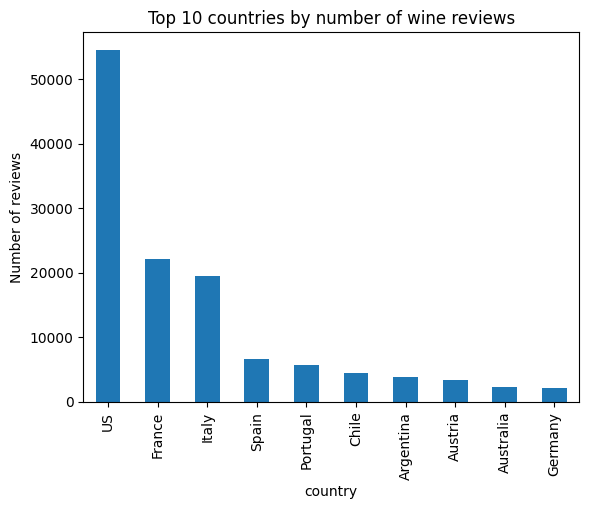

In [11]:

ax = df.country.value_counts().head(10).plot(kind='bar')
ax.set_title("Top 10 countries by number of wine reviews")
ax.set_ylabel("Number of reviews")